# NiftyGEX: one trading day through the pipeline

This notebook follows **12 June 2026** from the raw option file to the model inputs, one stage at a time. Each step shows a few rows, the rule the stage applies, and where to read more. It complements `01_input_datasets.ipynb` (the raw inputs) and the generated reports `docs/findings_data.md` and `docs/findings_forecast.md`.

The prediction snapshot is **15:15 IST**. The token history runs every 5 minutes from 09:20 to 15:15, and the options shown come from the day's nearest included expiry (16 June 2026).

*Run with the `Python 3.11 (niftygex)` kernel. The notebook only reads data; it never writes under `data/` or `outputs/`.*

In [2]:
import json
import sys
from datetime import date, datetime
from pathlib import Path
from zoneinfo import ZoneInfo

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "data.yaml").exists())
sys.path.insert(0, str(REPO / "src"))

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import polars as pl
from IPython.display import HTML, display

from niftygex.config import load_config
from niftygex.features.lineage import LINEAGE

CONFIG = load_config()
P = CONFIG["paths"]
IST = ZoneInfo("Asia/Kolkata")
DAY, EXPIRY = date(2026, 6, 12), date(2026, 6, 16)
SNAPSHOT = datetime(2026, 6, 12, 15, 15, tzinfo=IST)
BAR = datetime(2026, 6, 12, 15, 10, tzinfo=IST)  # the last bar usable at 15:15 (start-labeled, known at 15:15)
reports = Path(P["reports_root"])

SURFACE, TEXT, TEXT_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#e34948"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID, "axes.labelcolor": TEXT_2,
                     "axes.titlelocation": "left", "axes.titlesize": 11, "axes.grid": True, "grid.color": GRID,
                     "axes.spines.top": False, "axes.spines.right": False, "xtick.color": TEXT_2, "ytick.color": TEXT_2,
                     "legend.frameon": False, "figure.dpi": 110})


def show(frame) -> None:
    frame = frame.to_pandas() if isinstance(frame, pl.DataFrame) else frame
    display(HTML(frame.to_html(index=False, border=0, float_format=lambda v: f"{v:,.6g}")))


def near_money(frame: pl.DataFrame, center: float, width: float = 150) -> pl.DataFrame:
    return frame.filter(pl.col("strike_price").is_between(center - width, center + width))

## Step 1. Raw option bar

The source file holds one row per strike per 5-minute bar, exactly as delivered (`data/raw/`, never modified). The bar labeled 15:10 covers 15:10 to 15:15, so it is the last bar a 15:15 snapshot may use.

In [3]:
raw = pl.read_csv(P["raw_root"] / "options" / "NIFTY" / "2026" / f"NIFTY-call-{EXPIRY:%Y%m%d}.csv.gz")
raw_bar = raw.filter(pl.col("datetime") == f"{BAR:%Y-%m-%d %H:%M:%S}")
show(near_money(raw_bar, 23500).select("datetime", "expiry_date", "right", "strike_price", "close", "volume", "open_interest"))

datetime,expiry_date,right,strike_price,close,volume,open_interest
2026-06-12 15:10:00,2026-06-16,Call,"23,400",303.5,1039350,4473170
2026-06-12 15:10:00,2026-06-16,Call,"23,450",265.5,437710,1973595
2026-06-12 15:10:00,2026-06-16,Call,"23,500",229.6,2270320,6756360
2026-06-12 15:10:00,2026-06-16,Call,"23,350",343.65,354640,1195220
2026-06-12 15:10:00,2026-06-16,Call,"23,650",140.2,3728790,3150355
2026-06-12 15:10:00,2026-06-16,Call,"23,550",196.75,1393600,2388295
2026-06-12 15:10:00,2026-06-16,Call,"23,600",167,5381220,5962905


## Step 2. Cleaned bar (`scripts/clean_chain.py`)

Cleaning keeps the regular session (bars 09:15 to 15:25), drops holidays and special sessions, resolves duplicates deterministically, and adds `trade_date`, **`available_at` = label + 5 minutes** and day-level quality flags. The funnel shows what each rule removed across all option files.

In [4]:
cleaning = json.loads((reports / "cleaning_report.json").read_text())["row_counts"]["options"]
show(pd.DataFrame([("raw rows", cleaning["raw_rows"]), ("inside the project window", cleaning["after_date_range"]),
                   ("inside the regular session", cleaning["after_session"]), ("after excluded dates", cleaning["after_excluded_dates"]),
                   ("after deduplication", cleaning["after_dedup"])], columns=["step", "option rows"]))
curated = pl.read_parquet(P["curated_root"] / "options" / f"{EXPIRY:%Y}_NIFTY-call-{EXPIRY:%Y%m%d}.parquet")
show(near_money(curated.filter(pl.col("datetime") == BAR), 23500).select(
    "datetime", "available_at", "trade_date", "strike_price", "close", "volume", "open_interest", "data_quality"))

step,option rows
raw rows,22878869
inside the project window,22579580
inside the regular session,22547901
after excluded dates,22494288
after deduplication,22428331


datetime,available_at,trade_date,strike_price,close,volume,open_interest,data_quality
2026-06-12 15:10:00+05:30,2026-06-12 15:15:00+05:30,2026-06-12,"23,350",343.65,"354,640",1.19522e+06,ok
2026-06-12 15:10:00+05:30,2026-06-12 15:15:00+05:30,2026-06-12,"23,400",303.5,1.03935e+06,4.47317e+06,ok
2026-06-12 15:10:00+05:30,2026-06-12 15:15:00+05:30,2026-06-12,"23,450",265.5,"437,710",1.9736e+06,ok
2026-06-12 15:10:00+05:30,2026-06-12 15:15:00+05:30,2026-06-12,"23,500",229.6,2.27032e+06,6.75636e+06,ok
2026-06-12 15:10:00+05:30,2026-06-12 15:15:00+05:30,2026-06-12,"23,550",196.75,1.3936e+06,2.3883e+06,ok
2026-06-12 15:10:00+05:30,2026-06-12 15:15:00+05:30,2026-06-12,"23,600",167,5.38122e+06,5.9629e+06,ok
2026-06-12 15:10:00+05:30,2026-06-12 15:15:00+05:30,2026-06-12,"23,650",140.2,3.72879e+06,3.15036e+06,ok


## Step 3. Forward and implied volatility (`scripts/compute_forward.py`)

The forward is backed out from put–call parity on near-the-money pairs (median of the pairs). Implied volatility is solved with Black-76 against that forward; **both legs of a strike take the IV of the out-of-the-money leg** (calls above the forward, puts below), which gives one smooth smile.

datetime,available_at,forward,forward_pair_count,forward_residual_median_abs,forward_quality,time_to_expiry
2026-06-12 15:10:00+05:30,2026-06-12 15:15:00+05:30,"23,652.5",28,0.55,good,0.0109874


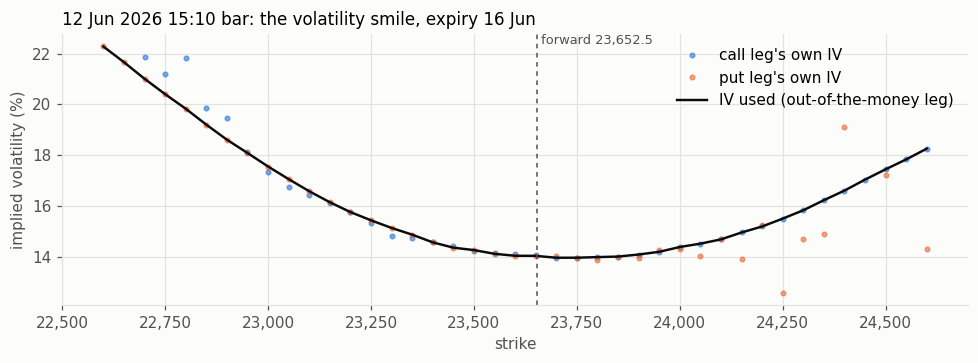

In [5]:
greeks_dir = Path(P["greeks_root"])
forward = pl.read_parquet(greeks_dir / "forward" / f"year={EXPIRY:%Y}" / f"expiry={EXPIRY:%Y%m%d}.parquet").filter(pl.col("datetime") == BAR)
show(forward.select("datetime", "available_at", "forward", "forward_pair_count", "forward_residual_median_abs", "forward_quality", "time_to_expiry"))
F = float(forward["forward"][0])

iv = pl.read_parquet(greeks_dir / "iv" / f"year={EXPIRY:%Y}" / f"expiry={EXPIRY:%Y%m%d}.parquet").filter(
    (pl.col("datetime") == BAR) & (pl.col("iv_status") == "ok")).sort("strike_price").to_pandas()
fig, ax = plt.subplots(figsize=(9, 3.4))
for right, color in (("Call", BLUE), ("Put", ORANGE)):
    part = iv[iv["right"] == right]
    ax.plot(part["strike_price"], part["iv_own"] * 100, ".", color=color, alpha=0.6, label=f"{right.lower()} leg's own IV")
smile = iv.drop_duplicates("strike_price")
ax.plot(smile["strike_price"], smile["iv"] * 100, color=TEXT, linewidth=1.6, label="IV used (out-of-the-money leg)")
ax.axvline(F, color=TEXT_2, linestyle=(0, (3, 3)), linewidth=1)
ax.text(F, ax.get_ylim()[1], f" forward {F:,.1f}", va="top", fontsize=8.5, color=TEXT_2)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xlabel("strike"); ax.set_ylabel("implied volatility (%)")
ax.set_title(f"{DAY:%d %b %Y} 15:10 bar: the volatility smile, expiry {EXPIRY:%d %b}")
ax.legend(loc="upper right")
fig.tight_layout(); plt.show()

## Step 4. Greeks (`scripts/compute_greeks.py`)

Black-76 gamma and delta for **eligible** legs only: traded, IV solved, a good forward, and positive time to expiry. Gamma peaks at the strikes nearest the forward, which is why near-the-money contracts dominate GEX.

strike_price,right,close,iv,gamma,delta,open_interest
"23,600",Call,167,0.140336,0.00113234,0.562878,5.9629e+06
"23,600",Put,114,0.140336,0.00113234,-0.437122,7.34461e+06
"23,650",Call,140.2,0.140311,0.0011467,0.505743,3.15036e+06
"23,650",Put,137.55,0.140311,0.0011467,-0.494257,2.08942e+06
"23,700",Call,115.7,0.13956,0.00114329,0.448294,6.21166e+06
"23,700",Put,164,0.13956,0.00114329,-0.551706,2.41482e+06
"23,750",Call,95,0.139577,0.00111038,0.392042,2.57186e+06
"23,750",Put,192.35,0.139577,0.00111038,-0.607958,"459,420"


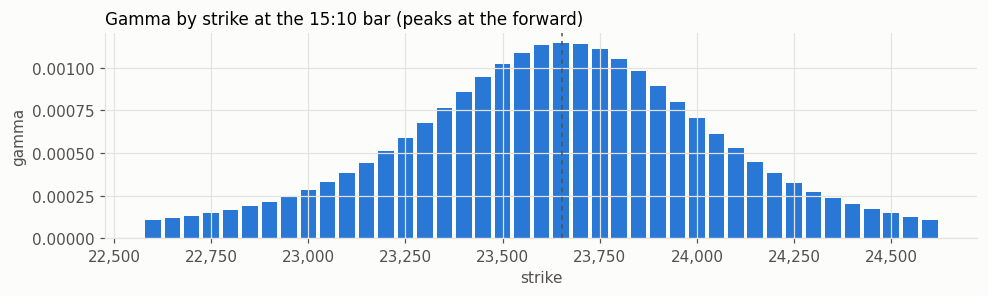

In [6]:
greeks = pl.read_parquet(greeks_dir / "greeks" / f"year={EXPIRY:%Y}" / f"expiry={EXPIRY:%Y%m%d}.parquet").filter(pl.col("datetime") == BAR)
show(near_money(greeks, F, 100).sort("strike_price", "right").select("strike_price", "right", "close", "iv", "gamma", "delta", "open_interest"))
by_strike = greeks.group_by("strike_price").agg(pl.col("gamma").mean()).sort("strike_price").to_pandas()
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.bar(by_strike["strike_price"], by_strike["gamma"], width=40, color=BLUE)
ax.axvline(F, color=TEXT_2, linestyle=(0, (3, 3)), linewidth=1)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xlabel("strike"); ax.set_ylabel("gamma"); ax.set_title("Gamma by strike at the 15:10 bar (peaks at the forward)")
fig.tight_layout(); plt.show()

## Step 5. GEX and key levels at the 15:15 snapshot (`scripts/compute_gex.py`)

For every contract, **GEX = gamma × open interest × spot² × 0.01**: rupees of hedging per 1% move. Open interest is in index units, so there is no lot multiplier. Totals are summed over expiries within 21 days (same-day expiries excluded for the next-day target) under three sign conventions:
- **naive:** calls +, puts −;
- **absolute:** every contract +;
- **inferred:** signs taken from the previous day's professional-trader positions.

In [7]:
exposure = Path(P["exposure_root"])
totals = pl.read_parquet(exposure / "gex_totals" / "gex_totals.parquet").filter(pl.col("snapshot_at") == SNAPSHOT)
levels = pl.read_parquet(exposure / "levels" / "levels.parquet").filter(pl.col("snapshot_at") == SNAPSHOT)
row, lev = totals.row(0, named=True), levels.row(0, named=True)
show(pd.DataFrame([("spot", f"{row['spot']:,.2f}"), ("expiries in total GEX", row["expiries"]), ("contracts (legs)", row["legs"]),
                   *[(f"total GEX, {c} (₹ crore per 1%)", f"{row[f'gex_{c}'] / 1e7:,.0f}") for c in ("naive", "absolute", "inferred")],
                   ("call wall", f"{lev['call_wall']:,.0f}"), ("put wall", f"{lev['put_wall']:,.0f}"), ("max pain", f"{lev['max_pain']:,.0f}"),
                   ("max-GEX strike", f"{lev['max_gex_strike']:,.0f}"), ("flip level (naive)", f"{lev['flip_naive']:,.1f}")],
                  columns=["quantity", "value at 15:15"]))

quantity,value at 15:15
spot,"23,621.80"
expiries in total GEX,3
contracts (legs),231
"total GEX, naive (₹ crore per 1%)","-4,296"
"total GEX, absolute (₹ crore per 1%)","114,885"
"total GEX, inferred (₹ crore per 1%)","114,885"
call wall,"24,000"
put wall,"23,000"
max pain,"23,500"
max-GEX strike,"23,500"


## Step 6. The 40 aggregate features: the classical models' inputs (`scripts/compute_features.py`)

One row per trading day at 15:15. Each feature is listed with its value on this day, its source dataset, and when that value becomes available; the mapping lives in `src/niftygex/features/lineage.py`. Daily sources (VIX, participant OI) enter from 09:15 on the next trading day.

In [8]:
features = pl.read_parquet(Path(P["features_root"]) / "aggregate" / "aggregate.parquet").filter(pl.col("snapshot_at") == SNAPSHOT)
feature_columns = json.loads((reports / "features_report.json").read_text())["feature_columns"]
values = features.row(0, named=True)
show(pd.DataFrame([(c, values[c], *LINEAGE[c]) for c in feature_columns], columns=["feature", "value", "group", "source", "available"]))

feature,value,group,source,available
spot,"23,621.8",Market state,NIFTY 50 index,bars available by the snapshot (15-minute staleness)
gex_total_naive,-4.29625e+10,Gamma exposure,NIFTY option chain + NIFTY 50 index,bars available by the snapshot (15-minute staleness)
gex_total_absolute,1.14885e+12,Gamma exposure,NIFTY option chain + NIFTY 50 index,bars available by the snapshot (15-minute staleness)
gex_total_inferred,1.14885e+12,Gamma exposure,NIFTY option chain + NIFTY 50 index + NSE participant OI (daily),bars available by the snapshot (15-minute staleness)
gex_expiries,3,Gamma exposure,NIFTY option chain,bars available by the snapshot (15-minute staleness)
includes_same_day_expiry,False,Gamma exposure,NIFTY option chain,bars available by the snapshot (15-minute staleness)
days_to_expiry,4,Calendar,NIFTY option chain,known in advance (listed expiries)
gex_concentration_hhi,0.0587633,Gamma exposure,NIFTY option chain + NIFTY 50 index,bars available by the snapshot (15-minute staleness)
call_wall_distance_pct,1.60106,Key levels,NIFTY option chain,bars available by the snapshot (15-minute staleness)
put_wall_distance_pct,-2.63231,Key levels,NIFTY option chain,bars available by the snapshot (15-minute staleness)


## Step 7. Token history: the sequence models' input (`scripts/compute_tokens.py`)

One token per liquid contract of the day's nearest expiry, at every 5-minute snapshot from 09:20 to 15:15. `lag` counts snapshots back from 15:15, so a GRU with a one-hour window reads lags 11 down to 0. First the 15:15 tokens near the money, then how strike GEX moved over the last hour.

5,541 token rows on 2026-06-12: 72 snapshots, 72–81 contracts each, expiry [datetime.date(2026, 6, 16)]


token_index,strike_price,right,log_moneyness,iv,gamma,delta,strike_gex_naive_crore,open_interest,oi_change_since_previous_close,volume_today
40,"23,600",Call,-0.00221999,0.140336,0.00113234,0.562878,"3,767.57",5.9629e+06,"-476,970",2.52574e+08
41,"23,600",Put,-0.00221999,0.140336,0.00113234,-0.437122,"-4,640.58",7.34461e+06,6.74356e+06,7.76994e+07
42,"23,650",Call,-0.000103589,0.140311,0.0011467,0.505743,"2,015.74",3.15036e+06,1.03792e+06,1.30489e+08
43,"23,650",Put,-0.000103589,0.140311,0.0011467,-0.494257,"-1,336.91",2.08942e+06,1.88513e+06,2.01762e+07
44,"23,700",Call,0.00200834,0.13956,0.00114329,0.448294,"3,962.68",6.21166e+06,"82,420",2.02171e+08
45,"23,700",Put,0.00200834,0.13956,0.00114329,-0.551706,"-1,540.51",2.41482e+06,1.94564e+06,2.24352e+07
46,"23,750",Call,0.00411583,0.139577,0.00111038,0.392042,"1,593.46",2.57186e+06,1.00288e+06,1.03047e+08
47,"23,750",Put,0.00411583,0.139577,0.00111038,-0.607958,-284.646,"459,420","394,485",4.0755e+06


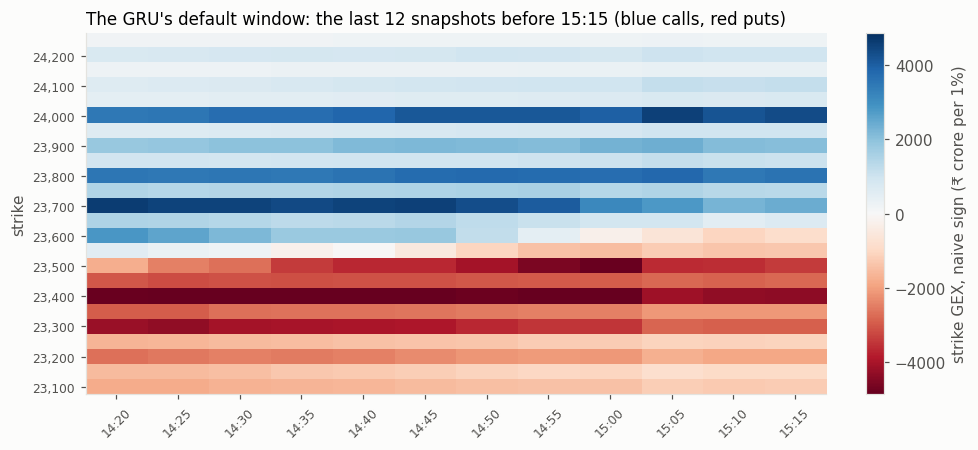

In [9]:
tokens = pl.read_parquet(Path(P["features_root"]) / "tokens" / f"year={DAY.year}.parquet").filter(pl.col("trade_date") == DAY)
per_lag = tokens.group_by("lag").len().sort("lag")
print(f"{tokens.height:,} token rows on {DAY}: {per_lag.height} snapshots, {per_lag['len'].min()}–{per_lag['len'].max()} contracts each, "
      f"expiry {tokens['expiry_date'].unique().to_list()}")
latest = tokens.filter(pl.col("lag") == 0)
show(near_money(latest, F, 100).select("token_index", "strike_price", "right", "log_moneyness", "iv", "gamma", "delta",
                                       "strike_gex_naive_crore", "open_interest", "oi_change_since_previous_close", "volume_today"))

hour = tokens.filter(pl.col("lag") < 12).group_by("snapshot_at", "strike_price").agg(pl.col("strike_gex_naive_crore").sum())
grid = hour.pivot(on="snapshot_at", index="strike_price", values="strike_gex_naive_crore").sort("strike_price")
grid = grid.filter(pl.col("strike_price").is_between(F - 600, F + 600))
times = sorted(c for c in grid.columns if c != "strike_price")
matrix = grid.select(times).to_numpy()
limit = np.nanpercentile(np.abs(matrix), 98)
fig, ax = plt.subplots(figsize=(9, 4.2))
image = ax.imshow(matrix, aspect="auto", origin="lower", cmap="RdBu", vmin=-limit, vmax=limit)
ax.set_xticks(range(len(times)), [t[11:16] for t in times], rotation=45, fontsize=8)
ax.set_yticks(range(0, grid.height, 2), [f"{k:,.0f}" for k in grid["strike_price"].to_list()[::2]], fontsize=8)
ax.grid(False); ax.set_ylabel("strike")
fig.colorbar(image, ax=ax, fraction=0.03).set_label("strike GEX, naive sign (₹ crore per 1%)")
ax.set_title("The GRU's default window: the last 12 snapshots before 15:15 (blue calls, red puts)")
fig.tight_layout(); plt.show()

## Step 8. Target (`scripts/compute_targets.py`)

The target is the **next trading day's** realized volatility of the front-month future relative to its trailing 20-day mean; models predict its log. It is stored apart from the features and only becomes known at 15:30 on the next trading day.

In [10]:
target = pl.read_parquet(Path(P["targets_root"]) / "t2" / "t2.parquet").filter(pl.col("snapshot_at") == SNAPSHOT).row(0, named=True)
show(pd.DataFrame([("forecast day", target["target_date"]), ("next-day RV", target["rv_next"]), ("trailing 20-day mean RV", target["rv_trailing_mean"]),
                   ("ratio", target["rv_ratio_trailing"]), ("log ratio (model outcome)", float(np.log(target["rv_ratio_trailing"]))),
                   ("tercile label", target["t2_label"]), ("known at", target["target_available_at"])], columns=["quantity", "value"]))
assert target["target_available_at"] > SNAPSHOT

quantity,value
forecast day,2026-06-15
next-day RV,0.00492745
trailing 20-day mean RV,0.00661968
ratio,0.744364
log ratio (model outcome),-0.295225
tercile label,low
known at,2026-06-15 15:30:00+05:30


## Step 9. Leakage check for this day

Every source a feature uses carries its availability time. All of them must be at or before 15:15; the validation stage runs the same check over every row and every source.

In [11]:
sources = [c for c in features.columns if c.endswith("_available_at")]
checks = pd.DataFrame([(c.removesuffix("_available_at"), values[c], (SNAPSHOT - values[c]).total_seconds() / 60 if values[c] else None) for c in sources],
                      columns=["source", "latest availability used", "minutes before 15:15"])
show(checks)
assert all(v is None or v <= SNAPSHOT for v in features.select(sources).row(0))
validation = json.loads((reports / "validation_report.json").read_text())
print(f"Whole sample: {len(validation['timestamp_and_leakage_checks'])} timestamp checks, all passed = {validation['all_leakage_checks_passed']}")

source,latest availability used,minutes before 15:15
gex_chain,2026-06-12 15:15:00+05:30,0
spot,2026-06-12 15:15:00+05:30,0
participant,2026-06-12 09:15:00+05:30,360
oi_chain,2026-06-12 15:15:00+05:30,0
eod_oi,2026-06-12 09:15:00+05:30,360
basis,2026-06-12 15:15:00+05:30,0
vix,NaT,NaN
futures_rv,2026-06-12 15:15:00+05:30,0
rv_trailing,2026-06-11 15:30:00+05:30,"1,425"
feature_max_source,2026-06-12 15:15:00+05:30,0


Whole sample: 20 timestamp checks, all passed = True


## Where to read more

| Topic | File |
|---|---|
| Every table and column | `docs/schema.md` |
| Feature and token figures | `docs/findings_data.md` |
| Classical baselines | `docs/findings_forecast.md` |
| Status and next steps | `docs/PROJECT_STATUS.md` |
| Feature sources (code) | `src/niftygex/features/lineage.py` |